# Creating a ground truth by using label transfer from one annotated slide to the other slides. 

In [2]:
from pathlib import Path
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from sklearn.neighbors import KNeighborsClassifier
import gc

%load_ext autoreload
%autoreload 2

sys.path.insert(0, str(Path("..").resolve()))
from functions import plotting as pl

In [6]:
basedir = Path("../data")
dir_uni =  "01_preprocessing/unimodel/metadata"
samples = ["CRC_P1", "CRC_P2", "CRC_P5", "Normal_P3", "Normal_P5", "CRC_P6_5mm", "CRC_P11mm"]

def label_transfer_dir(sample_id):
    """data/{sample}/02_baselines/label_transfer -- matches functions/label_transfer.py's OUT_DIR_TEMPLATE."""
    return basedir / sample_id / "02_baselines/label_transfer"

### Patch-level label transfer (the working pipeline)

Runs `functions/label_transfer.py` -- two classifiers (UNI image embeddings, and
aggregated-transcriptomics-per-patch) trained on the CRC_P2 ground truth and
applied to every other sample. Both the reference and every target are sourced
from `filtered_WSI_patch_embeddings.h5ad`, so background/no-tissue patches
(identified via the leiden-cluster filtering in `02_downstream_analysis_uni.ipynb`)
are excluded from training and prediction.

In [ ]:
import importlib
from functions import label_transfer as lt

importlib.reload(lt)  # pick up any edits without restarting the kernel

# min_compound_label_count: None -> collapse every tissuetype to its dominant
#   component (6 base classes). An int (e.g. 100) instead keeps common
#   border-region labels (e.g. "Veins_Neoplasm") as their own class.
# neoplasm_prior_weight_on_normal: None disables the prior entirely. 0.0 hard-masks
#   Neoplasm on "Normal_*" slides; e.g. 0.1 soft-downweights it instead.
# model_type: "mlp" (default, small GPU neural net) or "knn" (sklearn k-NN,
#   CPU, no training loop -- simpler, handles rare classes naturally).
lt.main(
    min_compound_label_count=50,
    neoplasm_prior_weight_on_normal=0.1,
    model_type="mlp",
)

In [ ]:
# Merge every target sample's predictions into one combined AnnData:
# data/combined/02_baselines/label_transfer/combined_patch_predictions.h5ad
# Uses discover_target_samples() so this always matches exactly what lt.main()
# just produced (CRC_P2 is the reference, not a prediction target, so it's
# excluded here too, same as in main()).
from functions.merge import merge_anndatas

merged_predictions = merge_anndatas(
    lt.discover_target_samples(),
    "{basedir}/{sample}/02_baselines/label_transfer/{filename}",
    "{sample}_patch_predictions.h5ad",
    basedir,
    obs_name_mode="unique",
    per_sample_pca_key=None,
)

In [ ]:
# plot one sample based on patch-level label transfer

sample_id = samples[0]  # swap for any sample_id you want to inspect or set string like "CRC_P1"
result_dir = label_transfer_dir(sample_id)
if sample_id == "CRC_P2":
    adata_sample = sc.read_h5ad(result_dir / f"{sample_id}_with_annotation.h5ad")
else:
    adata_sample = sc.read_h5ad(result_dir / f"{sample_id}_patch_predictions.h5ad")


# TODO: optionally fix spatial key, so spatial information can also be somewhere else
pl.plot_spatial_labels(
    adata_sample,
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  # or "predicted_tissuetype_transcriptomics"
    title=sample_id,
    mode="patch",
)
plt.show()

In [ ]:
#  plot all samples based on patch-level label transfer
#
# Each sample's predictions were saved separately, so we reload just .obs and
# .obsm["spatial"] for every sample (backed="r" avoids pulling the patch
# embeddings into RAM), tag each with Slide_ID, and build one lightweight
# AnnData purely for plotting.

obs_list, spatial_list = [], []

for sample_id in samples:
    out_file = label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions.h5ad"
    if not out_file.exists():
        continue

    a = sc.read_h5ad(out_file, backed="r")
    obs = a.obs.copy()
    obs["Slide_ID"] = sample_id
    obs_list.append(obs)
    spatial_list.append(np.asarray(a.obsm["spatial"]))
    del a

obs_all = pd.concat(obs_list, axis=0, ignore_index=True)
spatial_all = np.vstack(spatial_list)

# dummy 1-column X: we only need obs + obsm for plotting
adata_all = ad.AnnData(X=np.zeros((obs_all.shape[0], 1)), obs=obs_all)
adata_all.obsm["spatial"] = spatial_all
adata_all.obs["Slide_ID"] = adata_all.obs["Slide_ID"].astype("category")

pl.plot_spatial_labels_grid(
    adata_all,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  # swap to "predicted_tissuetype_transcriptomics" to compare
    ncols=4,
    mode="patch",
)
plt.show()

# Histology

### 1st ground truth: Assigning ground truth based on label to each patch 

In [ ]:
# IDEA
# 1. Match feature matrix with positions if not done yet
# 2. filter out all pixels <0
# 3. Load unfiltered patch metadata
# 4. Match each bin to a patch
# 5. Aggregate?
# 6. Store patch label in the patch information
# 7. transfer to the filtered patches?
# 8. Also store in combined files

### 2nd ground truth: leiden clustering on UNI PCA

We will perform three types of leiden clustering:
1. In the first step, we will perform leiden clustering on PCA values of UNI2-h patch embeddings separately for each slide.
2. During the second step, we perfom leiden clustering over all slides combined. However, we do not apply patch correction yet.
3. In the final step, we apply patch correction to see the differences. 

For step 2 and 3 we also test disease prediction capabilities.

**Step 1: Leiden per Sample**

In [12]:
sample = "CRC_P2"
adata_single = sc.read_h5ad(basedir / sample / dir_uni / "filtered_WSI_patch_embeddings.h5ad")
adata_combined = sc.read_h5ad(basedir / "combined" / dir_uni / "filtered_WSI_patch_embeddings.h5ad")

In [25]:
adata_combined

AnnData object with n_obs × n_vars = 85553 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0', 'tissuetype', 'tissuetype_confidence', 'n_visium_bins', 'leiden_0.2_per_slide'
    uns: 'pca_loadings_per_sample', 'pca_variance_ratio_per_sample', 'sample_order'
    obsm: 'X_pca_per_sample_raw', 'X_umap_per_sample_raw', 'spatial'
    layers: None (.X)

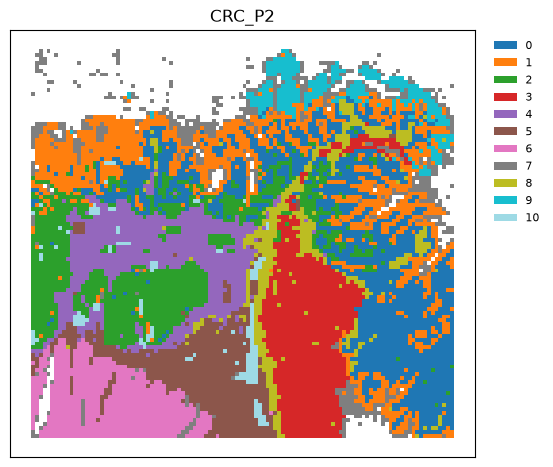

In [24]:
pl.plot_spatial_labels(
    adata_single,
    spatial_key="spatial",
    label_key="leiden_0.5",  
    title=sample,
    mode="patch",
)
plt.show()

For comparative overview, we now plot all images for PCA=50 and leiden resolution=0.2.

In [ ]:
# plot leiden for all, but independently (bc leiden was done independent)
# note: normal multi plotter uses same color for same cluster names and 
# making clusters independent requires too many colors for one plot with seven tiles for samples

**2nd step: Leiden WITHOUT batch correction over all samples**

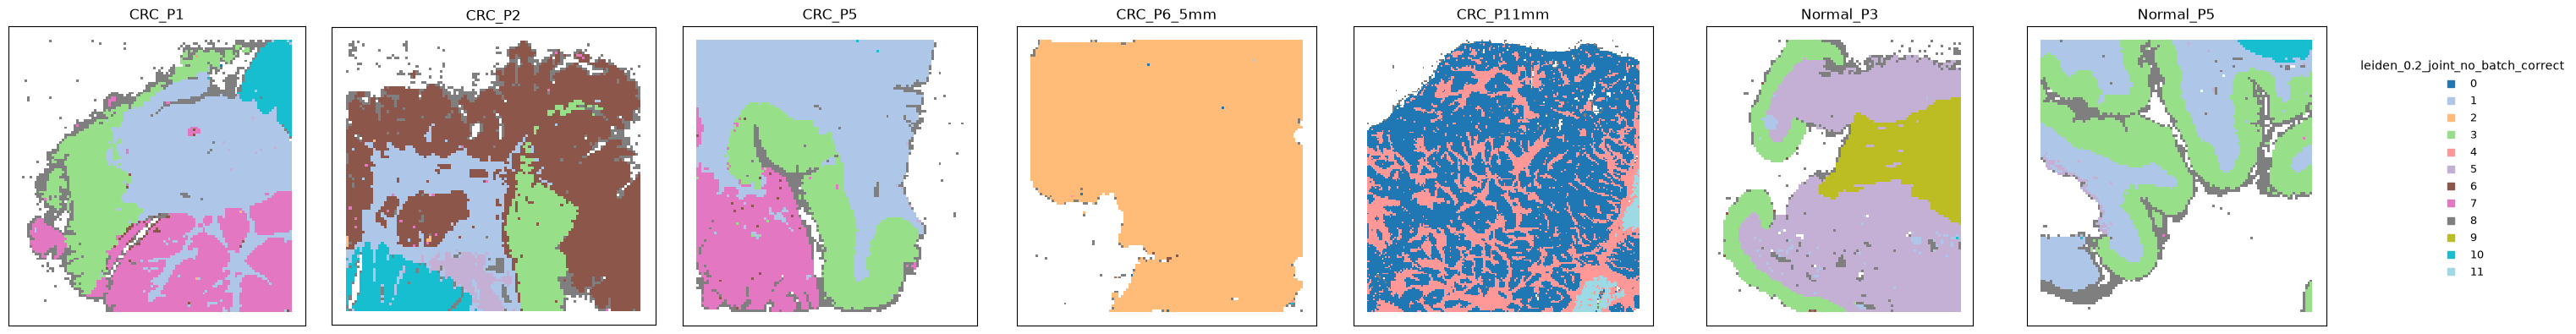

In [ ]:
# run PCA, neighbor graph and leiden on all samples at once
sc.pp.pca(adata_combined, n_comps=50)
sc.pp.neighbors(adata_combined)          
sc.tl.leiden(adata_combined, resolution=0.2, key_added="leiden_0.2_joint_no_batch_correct")

pl.plot_spatial_labels_grid(
    adata_combined,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="leiden_0.2_joint_no_batch_correct", 
    ncols=adata_combined.obs["Slide_ID"].nunique(), # or len(samples),
    mode="patch",
)
plt.show()

Now we test the disease prediction capabilites per slide.

In [38]:
# can we label diseased/non-diseased slides based on uni embeddings?
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from functions.label_transfer import get_disease_status
import numpy as np

X = adata_combined.obsm["X_pca"]  # the joint PCA, not the per-sample-raw one
y = (adata_combined.obs["Slide_ID"].map(get_disease_status) == "CRC").astype(int).to_numpy()

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X, y)
adata_combined.obs["diseased_pred_proba"] = clf.predict_proba(X)[:, 1]

groups = adata_combined.obs["Slide_ID"].to_numpy()
preds = np.zeros(len(y))

for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups):
    clf = LogisticRegression(max_iter=1000, class_weight="balanced")
    clf.fit(X[train_idx], y[train_idx])
    preds[test_idx] = clf.predict_proba(X[test_idx])[:, 1]

adata_combined.obs["diseased_pred_proba_loso"] = preds

summary = adata_combined.obs.groupby("Slide_ID")["diseased_pred_proba_loso"].agg(["mean", "std", "count"])
summary["disease_status"] = summary.index.map(get_disease_status)
print(summary)


                mean       std  count disease_status
Slide_ID                                            
CRC_P1      0.580502  0.394786   9197            CRC
CRC_P2      0.545823  0.394163   9592            CRC
CRC_P5      0.505419  0.402345   9467            CRC
CRC_P6_5mm  0.999701  0.004665  10983            CRC
CRC_P11mm   0.997526  0.020431  29959            CRC
Normal_P3   0.531182  0.370987   8292         Normal
Normal_P5   0.823047  0.285994   8063         Normal


/tmp/ipykernel_225528/1235606347.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = adata_combined.obs.groupby("Slide_ID")["diseased_pred_proba_loso"].agg(["mean", "std", "count"])


We also test how well the prediction works per patch. 
For this, we threshold the continuous `diseased_pred_proba_loso` from the previous cell into categories, then plot that categorical column with mode="patch" like every other label so far.

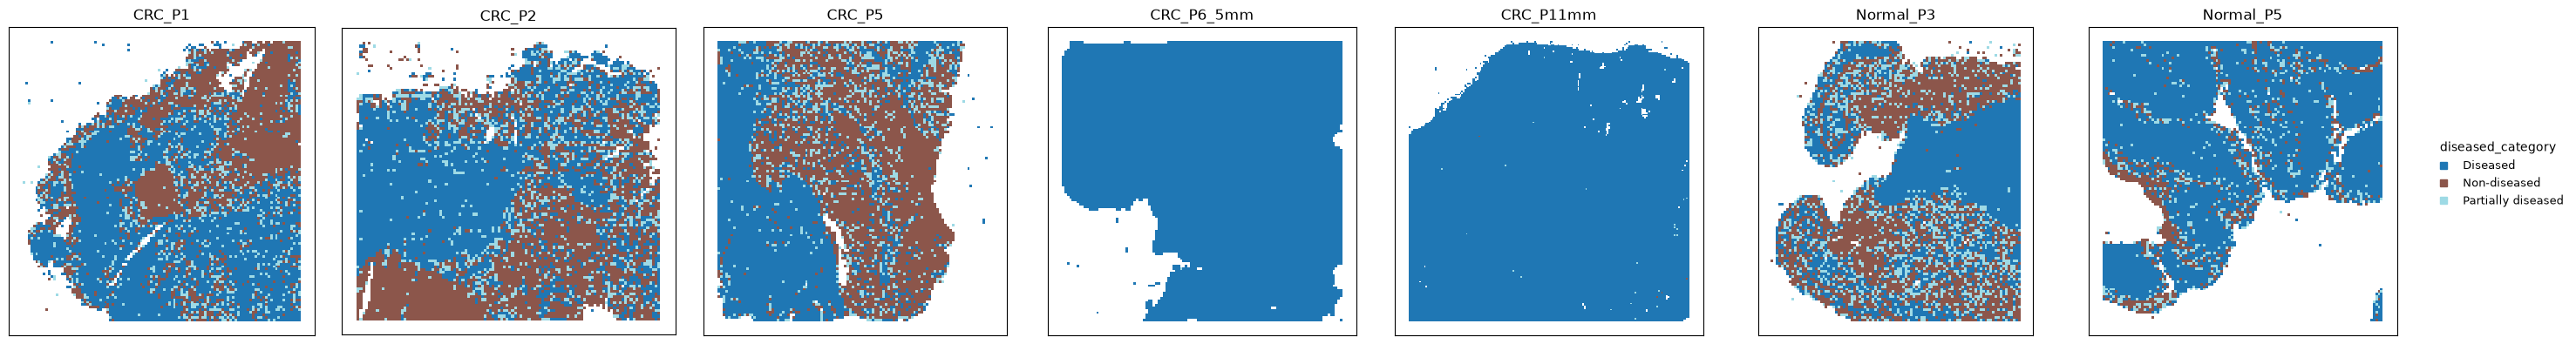

In [39]:
# If yes: can we plot diseased / partially diseased and non-diseased patches as binary masks? 
import numpy as np

# ternary: diseased / partially diseased / non-diseased (drop the middle band for a strict binary mask)
adata_combined.obs["diseased_category"] = np.select(
    [adata_combined.obs["diseased_pred_proba_loso"] <= 0.33,
     adata_combined.obs["diseased_pred_proba_loso"] >= 0.66],
    ["Non-diseased", "Diseased"],
    default="Partially diseased",
)
adata_combined.obs["diseased_category"] = adata_combined.obs["diseased_category"].astype("category")

pl.plot_spatial_labels_grid(
    adata_combined,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="diseased_category",
    ncols=len(samples),
    mode="patch",
)
plt.show()


**3rd: Leiden WITH batch correction** 

In [ ]:
# Issue:
# here, Slide_ID (the thing you'd batch-correct on) is in exact 1:1 correspondence with the label you're trying to predict. 
# Every slide has exactly one disease status — no two slides share a condition the way replicate samples usually do in scRNA-seq batch correction. 
# So "correct for Slide_ID" and "remove the disease signal" are mathematically the same operation here. Harmony (or any batch-correction method keyed on Slide_ID) 
# can't distinguish "this is slide-to-slide technical variation" from "this is the biological CRC-vs-Normal difference," 
# because nothing in the data lets it tell those apart — they're perfectly confounded.

### Compare UNI embeddings to label transfer

In [ ]:
### how

### Compare ?

# Transcriptomics

### 1st ground truth: assign labels to cells based on bin labeling
<span style="color:red">Check in eval: influence of lower UMI!!!.</span>

In [ ]:
# IDEA
# 1. Load filtered custom bins
# 2. Load unfiltered bins with annotation 
#    --> merge annotation to filtered custom bins (index should still be barcodes)
# 3. somehow aggregate annotation if they are not the same
# 4. transfer cell labels using cell id to count_area_filtered_adata
# 5. Compare ARI to ARI from just bins? wie ? 
# 6. Plot one or all samples

### 2nd ground truth: Clustering based on just HVGs

In [ ]:
# 1. Separate HVG was already performed: just cluster and plot
# 2. Try other leiden resolutions, plot cluster number per patch

In [ ]:
# 1. Combined HVG: calculate combined HVGs over all samples
# 2. Cluster again and plot leiden resolution cluster results
# 3. Also check: can we see diseased status per patient? 
# 4. Potentially: plot dieseased and healthy tissue as binary mask

### 3rd Ground truth: Clustering based on just SVGs

In [6]:
# same as above

### 4th ground truth: Clustering based on just PCA

In [ ]:
# same as above

### 5th Ground truth: Any SpaceRanger outputs?

In [ ]:
# same as above

## Baselines

### Potentially Autoencoder without smaller patches just the big ones? 